



# **ANALISIS PERUBAHAN HARGA PANGAN DI PROVINSI-PROVINSI DI PULAU JAWA (Desember 2023 - September 2026)**

##### Oleh : Yasyfa Maisun Majidah
##### Goals :

1. Mengidentifikasi komoditas dan provinsi di Pulau Jawa yang paling terdampak lonjakan harga pangan pada 2026.
2. Menilai apakah harga September 2026 tergolong tinggi dibanding kebiasaan harga tiap provinsi sendiri, bukan hanya dibanding setahun lalu.
3. Menguji apakah perubahan harga pangan berkaitan dengan inflasi bulanan.

**Cakupan :** 6 komoditas, 6 provinsi di Pulau Jawa, Desember 2023 - September 2026.

**Sumber data :** PIHPS Bank Indonesia dan BPS

**Di luar cakupan :** prediksi harga, pembuktian sebab-akibat, dan faktor pendorong (kurs, cuaca, musiman).

In [62]:
#setup

import pandas as pd
import numpy as np
import os, glob, re
from datetime import datetime

from google.colab import drive
drive.mount("/content/drive")

try:
  display
except NameError:
  display = print

BASE = "/content/drive/MyDrive/proyek-harga-pangan"
BATAS_INFLASI = "2026-08"
LIMIT_ISI = 3
AMBANG_OUTLIER = 0.5
HAPUS_OUTLIER = False

RAW_PIHPS = f"{BASE}/data/raw/pihps"
RAW_INFL = f"{BASE}/data/raw/inflasi"
CLEAN = f"{BASE}/data/clean"
os.makedirs(CLEAN, exist_ok=True)

PROVINSI_JAWA = ["Banten", "Jawa Barat", "DKI Jakarta", "Jawa Tengah", "DI Yogyakarta", "Jawa Timur"]
catatan = {}

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [63]:
#baca data pihps

##bersihkan tanggal
def parse_tanggal(c):
    """Header tanggal bisa berupa tanggal asli Excel atau teks seperti '01/ 12/ 2023'."""
    if isinstance(c, (datetime, pd.Timestamp)):
        return pd.Timestamp(c)
    s = re.sub(r"\s+", "", str(c))
    return pd.to_datetime(s, dayfirst=True, errors="coerce")

##bersihkan harga
def bersihkan_harga(x):
    """Ubah harga teks/angka jadi float. Menangani 'Rp', spasi, pemisah ribuan (titik atau koma), dan '-'."""
    s = x.astype(str).str.replace(r"[Rr]p|\s", "", regex=True)
    s = s.str.replace(r"(?<=\d)[.,](?=\d{3}(?!\d))", "", regex=True)
    return pd.to_numeric(s, errors="coerce")


def baca_pihps(path):
    # mengambil nama komoditas dari nama file
    nama = os.path.basename(path)
    stem = os.path.splitext(nama)[0].lower()
    komoditas, _, varian = stem.partition("_")
    varian = varian or "semua"

    # dtype=str: cegah pandas mengubah teks seperti '14.650' menjadi 14.65 sebelum dibersihkan
    df = pd.read_excel(path, dtype=str)
    df = df.rename(columns={df.columns[0]: "no", df.columns[1]: "provinsi"})
    df = df.drop(columns="no").dropna(subset=["provinsi"])
    df["provinsi"] = df["provinsi"].astype(str).str.strip()

    # ubah dari lebar ke panjang
    long = df.melt(id_vars="provinsi", var_name="kolom", value_name="harga_raw")
    long["tanggal"] = long["kolom"].map(parse_tanggal)
    gagal = long.loc[long["tanggal"].isna(), "kolom"].unique()
    if len(gagal):
        print(f"  ! {nama}: {len(gagal)} header tanggal gagal dibaca, contoh: {list(gagal[:3])}")
    long = long.dropna(subset=["tanggal"]).copy()

    long["harga"] = bersihkan_harga(long["harga_raw"])
    long["komoditas"] = komoditas
    long["varian"] = varian
    long["jenis"] = np.where(long["provinsi"].str.lower() == "semua provinsi", "nasional", "provinsi")
    long["sumber_file"] = nama
    return long[["komoditas", "varian", "provinsi", "jenis", "tanggal", "harga", "sumber_file"]]


files = sorted(glob.glob(f"{RAW_PIHPS}/*.xlsx"))
print(len(files), "file PIHPS ditemukan")
pihps = pd.concat([baca_pihps(f) for f in files], ignore_index=True)
print("Bentuk data:", pihps.shape)

6 file PIHPS ditemukan
Bentuk data: (31038, 7)


In [64]:
#audit awal

print("Provinsi yang terbaca:", sorted(pihps["provinsi"].unique()))
print("Rentang tanggal:", pihps["tanggal"].min().date(), "sampai", pihps["tanggal"].max().date())
n_weekend = int(pihps["tanggal"].dt.dayofweek.isin([5, 6]).sum())
print("Baris di Sabtu/Minggu:", n_weekend, "(biasanya 0; kalau banyak, cek apakah hari dan bulan tertukar)")

ringkas = (pihps.groupby(["komoditas", "varian"])
           .agg(awal=("tanggal", "min"), akhir=("tanggal", "max"),
                n_hari=("tanggal", "nunique"), n_provinsi=("provinsi", "nunique")))
display(ringkas)

Provinsi yang terbaca: ['Banten', 'DI Yogyakarta', 'DKI Jakarta', 'Jawa Barat', 'Jawa Tengah', 'Jawa Timur', 'Semua Provinsi']
Rentang tanggal: 2023-12-01 sampai 2026-09-30
Baris di Sabtu/Minggu: 0 (biasanya 0; kalau banyak, cek apakah hari dan bulan tertukar)


,,awal,akhir,n_hari,n_provinsi
komoditas,varian,,,,
bawang-merah,semua,2023-12-01,2026-09-30,739,7
beras-medium-i,semua,2023-12-01,2026-09-30,739,7
cabai-merah-keriting,semua,2023-12-01,2026-09-30,739,7
cabai-rawit-merah,semua,2023-12-01,2026-09-30,739,7
daging-ayam,semua,2023-12-01,2026-09-30,739,7
telur-ayam,semua,2023-12-01,2026-09-30,739,7


In [65]:
#cleaning PIHPS

kunci = ["komoditas", "varian", "provinsi", "tanggal"]
grup = ["komoditas", "varian", "provinsi"]

# 1) buang duplikat (misal dua file saling tumpang tindih)
n_dup = int(pihps.duplicated(subset=kunci).sum())
pihps = pihps.drop_duplicates(subset=kunci, keep="last")
print("Duplikat dibuang:", n_dup)

# 2) harga tidak valid
n_nol = int((pihps["harga"] <= 0).sum())
pihps.loc[pihps["harga"] <= 0, "harga"] = np.nan
print("Harga <= 0 dijadikan kosong:", n_nol)

# 3) persentase data kosong per komoditas x provinsi
kosong = (pihps.groupby(grup)["harga"].apply(lambda x: x.isna().mean() * 100).round(1))
print("Persentase harga kosong (sebelum diisi):")
## mengubah tabel panjang menjadi lebar
display(kosong.unstack())

# 4) isi kekosongan pendek dengan harga sebelumnya
pihps = pihps.sort_values(kunci).reset_index(drop=True)
pihps["harga_bersih"] = pihps.groupby(grup)["harga"].ffill(limit=LIMIT_ISI)
pihps["diisi"] = pihps["harga"].isna() & pihps["harga_bersih"].notna()
print("Sel diisi:", int(pihps["diisi"].sum()), "| masih kosong:", int(pihps["harga_bersih"].isna().sum()))

# 5) tandai outlier (dibanding median bergulir ~3 minggu kerja); data tidak dibuang otomatis
med = pihps.groupby(grup)["harga_bersih"].transform(
    lambda x: x.rolling(15, center=True, min_periods=5).median())
pihps["outlier"] = ((pihps["harga_bersih"] / med) - 1).abs() > AMBANG_OUTLIER
n_out = int(pihps["outlier"].sum())
print("Outlier ditandai:", n_out)
if n_out:
    display(pihps.loc[pihps["outlier"], kunci + ["harga", "harga_bersih"]].head(20))
if HAPUS_OUTLIER:
    pihps.loc[pihps["outlier"], "harga_bersih"] = np.nan

catatan.update(duplikat_dibuang=n_dup, harga_nol=n_nol,
               sel_diisi=int(pihps["diisi"].sum()), outlier_ditandai=n_out,
               hapus_outlier=HAPUS_OUTLIER, limit_isi_hari=LIMIT_ISI)

Duplikat dibuang: 0
Harga <= 0 dijadikan kosong: 0
Persentase harga kosong (sebelum diisi):


,provinsi,Banten,DI Yogyakarta,DKI Jakarta,Jawa Barat,Jawa Tengah,Jawa Timur,Semua Provinsi
komoditas,varian,,,,,,,
bawang-merah,semua,0.5,0.4,0.8,0.3,0.0,0.0,0.0
beras-medium-i,semua,0.5,0.4,0.8,0.3,0.0,0.0,0.0
cabai-merah-keriting,semua,0.5,0.4,0.8,0.3,0.0,0.0,0.0
cabai-rawit-merah,semua,0.5,0.4,0.8,0.3,0.0,0.0,0.0
daging-ayam,semua,0.5,0.4,0.9,0.3,0.0,0.0,0.0
telur-ayam,semua,0.5,0.4,0.9,0.3,0.0,0.0,0.0


Sel diisi: 92 | masih kosong: 0
Outlier ditandai: 3


,komoditas,varian,provinsi,tanggal,harga,harga_bersih
10751,cabai-merah-keriting,semua,Banten,2025-06-20,71500.0,71500.0
12150,cabai-merah-keriting,semua,DKI Jakarta,2025-03-03,91800.0,91800.0
15924,cabai-rawit-merah,semua,Banten,2025-06-20,93400.0,93400.0


In [66]:
# Agregasi bulanan dan perubahan bulanan (MoM)
pihps["bulan"] = pihps["tanggal"].dt.to_period("M")

bln = (pihps.groupby(grup + ["jenis", "bulan"])
       .agg(harga_bln=("harga_bersih", "mean"), n_hari=("harga_bersih", "count"))
       .reset_index()
       .sort_values(grup + ["bulan"])
       .reset_index(drop=True))

# perubahan bulanan; hanya dihitung kalau bulan sebelumnya benar-benar berurutan
prev_harga = bln.groupby(grup)["harga_bln"].shift(1)
prev_bulan = bln.groupby(grup)["bulan"].shift(1)
berurutan = (bln["bulan"] - prev_bulan).map(lambda d: getattr(d, "n", np.nan)) == 1
bln["mtm_pct"] = np.where(berurutan, (bln["harga_bln"] / prev_harga - 1) * 100, np.nan)
bln["data_tipis"] = bln["n_hari"] < 10

print("Bulan dengan data tipis (< 10 hari):", int(bln["data_tipis"].sum()))
display(bln.groupby(grup)["bulan"].agg(["min", "max", "nunique"]))

Bulan dengan data tipis (< 10 hari): 0


min      max  nunique
komoditas            varian provinsi                                 
bawang-merah         semua  Banten          2023-12  2026-09       34
                            DI Yogyakarta   2023-12  2026-09       34
                            DKI Jakarta     2023-12  2026-09       34
                            Jawa Barat      2023-12  2026-09       34
                            Jawa Tengah     2023-12  2026-09       34
                            Jawa Timur      2023-12  2026-09       34
                            Semua Provinsi  2023-12  2026-09       34
beras-medium-i       semua  Banten          2023-12  2026-09       34
                            DI Yogyakarta   2023-12  2026-09       34
                            DKI Jakarta     2023-12  2026-09       34
                            Jawa Barat      2023-12  2026-09       34
                            Jawa Tengah     2023-12  2026-09       34
                            Jawa Timur      2023-12  2026-09       34
                            Semua Provinsi  2023-12  2026-09       34
cabai-merah-keriting semua  Banten          2023-12  2026-09       34
                            DI Yogyakarta   2023-12  2026-09       34
                            DKI Jakarta     2023-12  2026-09       34
                            Jawa Barat      2023-12  2026-09       34
                            Jawa Tengah     2023-12  2026-09       34
                            Jawa Timur      2023-12  2026-09       34
                            Semua Provinsi  2023-12  2026-09       34
cabai-rawit-merah    semua  Banten          2023-12  2026-09       34
                            DI Yogyakarta   2023-12  2026-09       34
                            DKI Jakarta     2023-12  2026-09       34
                            Jawa Barat      2023-12  2026-09       34
                            Jawa Tengah     2023-12  2026-09       34
                            Jawa Timur      2023-12  2026-09       34
                            Semua Provinsi  2023-12  2026-09       34
daging-ayam          semua  Banten          2023-12  2026-09       34
                            DI Yogyakarta   2023-12  2026-09       34
                            DKI Jakarta     2023-12  2026-09       34
                            Jawa Barat      2023-12  2026-09       34
                            Jawa Tengah     2023-12  2026-09       34
                            Jawa Timur      2023-12  2026-09       34
                            Semua Provinsi  2023-12  2026-09       34
telur-ayam           semua  Banten          2023-12  2026-09       34
                            DI Yogyakarta   2023-12  2026-09       34
                            DKI Jakarta     2023-12  2026-09       34
                            Jawa Barat      2023-12  2026-09       34
                            Jawa Tengah     2023-12  2026-09       34
                            Jawa Timur      2023-12  2026-09       34
                            Semua Provinsi  2023-12  2026-09       34

In [67]:
#baca data inflasi

BULAN = {"Januari": 1, "Februari": 2, "Maret": 3, "April": 4, "Mei": 5, "Juni": 6,
         "Juli": 7, "Agustus": 8, "September": 9, "Oktober": 10, "November": 11, "Desember": 12}


def baca_inflasi(path):
    nama = os.path.basename(path)
    meta = pd.read_excel(path, header=None, nrows=3)
    ketemu = re.findall(r"20\d{2}", " ".join(str(v) for v in meta.values.ravel()))
    if not ketemu:
        raise ValueError(f"Tahun tidak ditemukan di 3 baris pertama {nama}")
    tahun = int(ketemu[0])

    df = pd.read_excel(path, header=3)
    df = df.rename(columns={df.columns[0]: "kota"}).dropna(subset=["kota"])
    kol = {c: BULAN[str(c).strip()] for c in df.columns[1:] if str(c).strip() in BULAN}
    df = df[["kota"] + list(kol)].rename(columns=kol)

    long = df.melt(id_vars="kota", var_name="bln", value_name="inflasi_raw")
    long["bulan"] = pd.to_datetime(long["bln"].map(lambda m: f"{tahun}-{int(m):02d}-01")).dt.to_period("M")
    long["inflasi_mtm"] = pd.to_numeric(
        long["inflasi_raw"].astype(str).str.replace(",", ".", regex=False), errors="coerce")
    long["kota"] = long["kota"].astype(str).str.strip().str.lower()
    long["sumber_file"] = nama
    return long[["kota", "bulan", "inflasi_mtm", "sumber_file"]]


files_infl = sorted(glob.glob(f"{RAW_INFL}/*.xlsx"))
print(len(files_infl), "file inflasi ditemukan")
infl = pd.concat([baca_inflasi(f) for f in files_infl], ignore_index=True)

print("Jumlah kota:", infl["kota"].nunique())
print("Duplikat kota x bulan:", int(infl.duplicated(subset=["kota", "bulan"]).sum()), "(harus 0)")
print("Jumlah kota dengan nilai per bulan (6 bulan terakhir):")
print(infl.groupby("bulan")["inflasi_mtm"].count().tail(6))

3 file inflasi ditemukan
Jumlah kota: 152
Duplikat kota x bulan: 0 (harus 0)
Jumlah kota dengan nilai per bulan (6 bulan terakhir):
bulan
2026-07    151
2026-08    151
2026-09      0
2026-10      0
2026-11      0
2026-12      0
Freq: M, Name: inflasi_mtm, dtype: int64


In [68]:
#pemetaan kota ke provinsi

PETA_KOTA = {
    "DKI JAKARTA" : "DKI JAKARTA",
    "KAB BANDUNG" : "JAWA BARAT",
    "KAB MAJALENGKA" : "JAWA BARAT",
    "KAB SUBANG" : "JAWA BARAT",
    "KOTA BOGOR" : "JAWA BARAT",
    "KOTA SUKABUMI" : "JAWA BARAT",
    "KOTA BANDUNG" : "JAWA BARAT",
    "KOTA CIREBON" : "JAWA BARAT",
    "KOTA BEKASI" : "JAWA BARAT",
    "KOTA DEPOK" : "JAWA BARAT",
    "KOTA TASIKMALAYA" : "JAWA BARAT",
    "CILACAP" : "JAWA TENGAH",
    "PURWOKERTO" : "JAWA TENGAH",
    "KAB WONOSOBO" : "JAWA TENGAH",
    "KAB WONOGIRI" : "JAWA TENGAH",
    "KAB REMBANG" : "JAWA TENGAH",
    "KUDUS" : "JAWA TENGAH",
    "KOTA SURAKARTA" : "JAWA TENGAH",
    "KOTA SEMARANG" : "JAWA TENGAH",
    "KOTA TEGAL" : "JAWA TENGAH",
    "KAB GUNUNGKIDUL" : "DI YOGYAKARTA",
    "KOTA YOGYAKARTA" : "DI YOGYAKARTA",
    "KAB TULUNGAGUNG" : "JAWA TIMUR",
    "JEMBER" : "JAWA TIMUR",
    "SUMENEP" : "JAWA TIMUR",
    "BANYUWANGI" : "JAWA TIMUR",
    "KAB BOJONEGORO" : "JAWA TIMUR",
    "KAB GRESIK" : "JAWA TIMUR",
    "KOTA MALANG" : "JAWA TIMUR",
    "KOTA PROBOLINGGO" : "JAWA TIMUR",
    "KOTA MADIUN" : "JAWA TIMUR",
    "KOTA SURABAYA" : "JAWA TIMUR",
    "KOTA KEDIRI" : "JAWA TIMUR",
    "KAB PANDEGLANG" : "BANTEN",
    "KAB LEBAK" : "BANTEN",
    "KOTA TANGERANG" : "BANTEN",
    "KOTA CILEGON" : "BANTEN",
    "KOTA SERANG" : "BANTEN",
}

PETA_KOTA = {k.strip().lower(): v.strip() for k, v in PETA_KOTA.items()}
_koreksi = {p.lower(): p for p in PROVINSI_JAWA}
PETA_KOTA = {k: _koreksi.get(v.lower(), v) for k, v in PETA_KOTA.items()}

if not PETA_KOTA:
    print("PETA_KOTA masih kosong. Daftar kota di file inflasi:")
    for k in sorted(infl["kota"].unique()):
        print(k)

In [69]:
# cek kota yang belum terpetakan
sisa = sorted(set(infl["kota"]) - set(PETA_KOTA))
print(len(sisa), "kota belum terpetakan")
print(sisa)

114 kota belum terpetakan
['bulukumba', 'bungo', 'dili', 'indonesia', 'kab aceh tamiang', 'kab aceh tengah', 'kab badung', 'kab bangka barat', 'kab belitung timur', 'kab berau', 'kab deli serdang', 'kab dharmasraya', 'kab gorontalo', 'kab halmahera tengah', 'kab hulu sungai tengah', 'kab jayawijaya', 'kab kampar', 'kab kapuas', 'kab karimun', 'kab karo', 'kab kayong utara', 'kab kerinci', 'kab ketapang', 'kab kolaka', 'kab konawe', 'kab labuhanbatu', 'kab lampung timur', 'kab luwu timur', 'kab majene', 'kab maluku tengah', 'kab mesuji', 'kab minahasa selatan', 'kab minahasa utara', 'kab morowali', 'kab muara enim', 'kab muko muko', 'kab nabire', 'kab ngada', 'kab nunukan', 'kab ogan komering ilir', 'kab pasaman barat', 'kab penajam paser utara', 'kab sidenreng rappang', 'kab sorong', 'kab sorong selatan', 'kab sukamara', 'kab sumbawa', 'kab tabanan', 'kab tanah laut', 'kab timor tengah selatan', 'kab toli toli', 'kab wajo', 'kota ambon', 'kota balikpapan', 'kota banda aceh', 'kota band

In [70]:
#proses pemetaan

if not PETA_KOTA:
    print("Isi PETA_KOTA di sel sebelumnya dulu, lalu jalankan ulang sel ini.")
else:
    salah = set(PETA_KOTA.values()) - set(PROVINSI_JAWA)
    tidak_ada = [k for k in PETA_KOTA if k not in set(infl["kota"])]
    print("Nama provinsi tidak dikenal:", salah or "tidak ada")
    print("Kota di PETA_KOTA yang tidak ada di file inflasi:", tidak_ada or "tidak ada")

    infl_jawa = infl[infl["kota"].isin(PETA_KOTA)].copy()
    infl_jawa["provinsi"] = infl_jawa["kota"].map(PETA_KOTA)

    # rata-rata sederhana inflasi kota per provinsi (bukan inflasi resmi provinsi BPS)
    infl_prov = (infl_jawa.groupby(["provinsi", "bulan"])
                 .agg(inflasi_mtm=("inflasi_mtm", "mean"), n_kota=("inflasi_mtm", "count"))
                 .reset_index())
    infl_prov = infl_prov[(infl_prov["n_kota"] > 0) & (infl_prov["bulan"] <= pd.Period(BATAS_INFLASI))]

    print("Jumlah kota per provinsi (min dan maks sepanjang waktu; sebaiknya stabil):")
    display(infl_prov.groupby("provinsi")["n_kota"].agg(["min", "max"]))
    print("Kota per provinsi:")
    display(pd.Series(PETA_KOTA).value_counts().rename("jumlah_kota"))

Nama provinsi tidak dikenal: tidak ada
Kota di PETA_KOTA yang tidak ada di file inflasi: tidak ada
Jumlah kota per provinsi (min dan maks sepanjang waktu; sebaiknya stabil):


,min,max
provinsi,,
Banten,5,5
DI Yogyakarta,2,2
DKI Jakarta,1,1
Jawa Barat,10,10
Jawa Tengah,9,9
Jawa Timur,11,11


Kota per provinsi:


,jumlah_kota
Jawa Timur,11
Jawa Barat,10
Jawa Tengah,9
Banten,5
DI Yogyakarta,2
DKI Jakarta,1


In [71]:
#gabungkan dan simpan

def simpan(df, nama):
    d = df.copy()
    for c in d.columns:
        if str(d[c].dtype).startswith("period"):
            d[c] = d[c].astype(str)
    d.to_csv(f"{CLEAN}/{nama}", index=False)
    print("Tersimpan:", nama, d.shape)


simpan(pihps.drop(columns=["bulan"]), "pihps_harian_bersih.csv")
simpan(bln, "pihps_bulanan.csv")

if PETA_KOTA:
    gabung = (bln[bln["jenis"] == "provinsi"]
              .merge(infl_prov, on=["provinsi", "bulan"], how="inner")
              .dropna(subset=["mtm_pct", "inflasi_mtm"]))
    print("Baris gabungan:", len(gabung), "| bulan:", gabung["bulan"].min(), "sampai", gabung["bulan"].max())
    simpan(infl_prov, "inflasi_provinsi_bulanan.csv")
    simpan(gabung, "gabungan_harga_inflasi.csv")
else:
    print("Penggabungan dengan inflasi dilewati karena PETA_KOTA masih kosong.")

print("\nCatatan keputusan cleaning (salin ke README):")
for k, v in catatan.items():
    print(f"- {k}: {v}")

print(gabung.shape)                              # harus (1152, 11)
print(gabung.groupby("komoditas").size())        # 192 per komoditas
print(gabung[["mtm_pct", "inflasi_mtm"]].describe().round(2))
print(gabung.bulan.min(), gabung.bulan.max())    # 2024-01 sampai 2026-08

Tersimpan: pihps_harian_bersih.csv (31038, 10)
Tersimpan: pihps_bulanan.csv (1428, 9)
Baris gabungan: 1152 | bulan: 2024-01 sampai 2026-08
Tersimpan: inflasi_provinsi_bulanan.csv (192, 4)
Tersimpan: gabungan_harga_inflasi.csv (1152, 11)

Catatan keputusan cleaning (salin ke README):
- duplikat_dibuang: 0
- harga_nol: 0
- sel_diisi: 92
- outlier_ditandai: 3
- hapus_outlier: False
- limit_isi_hari: 3
(1152, 11)
komoditas
bawang-merah            192
beras-medium-i          192
cabai-merah-keriting    192
cabai-rawit-merah       192
daging-ayam             192
telur-ayam              192
dtype: int64
       mtm_pct  inflasi_mtm
count  1152.00      1152.00
mean      1.17         0.19
std      19.16         0.50
min     -58.57        -1.50
25%      -4.93        -0.11
50%       0.00         0.18
75%       5.47         0.41
max     107.11         2.05
2024-01 2026-08


## Analisis Deskriptif (Jan 2024 - Sept 2026)

In [72]:
prov = bln[bln["jenis"] == "provinsi"].copy()

# volatilitas: simpangan baku perubahan bulanan, per komoditas
prov = bln[bln["jenis"] == "provinsi"].copy()

## jendela September 2025 - September 2026 (13 bulan)
prov_12 = prov[prov["bulan"] >= pd.Period("2025-09")]
vol = prov_12.groupby("komoditas")["mtm_pct"].std().sort_values(ascending=False).round(2)
display(vol)

# perubahan year-on-year (rata-rata 6 provinsi Jawa)
nas = prov.groupby(["komoditas", "bulan"])["harga_bln"].mean().unstack("komoditas")
yoy = (nas / nas.shift(12) - 1) * 100
display(yoy.tail(3).round(1).T)


,mtm_pct
komoditas,
cabai-rawit-merah,36.24
cabai-merah-keriting,20.07
bawang-merah,12.44
daging-ayam,7.99
telur-ayam,4.27
beras-medium-i,0.80


bulan,2026-07,2026-08,2026-09
komoditas,,,
bawang-merah,-16.2,-29.2,-14.9
beras-medium-i,2.3,2.7,3.6
cabai-merah-keriting,-2.7,4.3,-8.9
cabai-rawit-merah,-17.8,48.9,91.5
daging-ayam,4.3,20.0,6.8
telur-ayam,-11.3,-9.7,-8.0


## Analisis Tren & Puncak

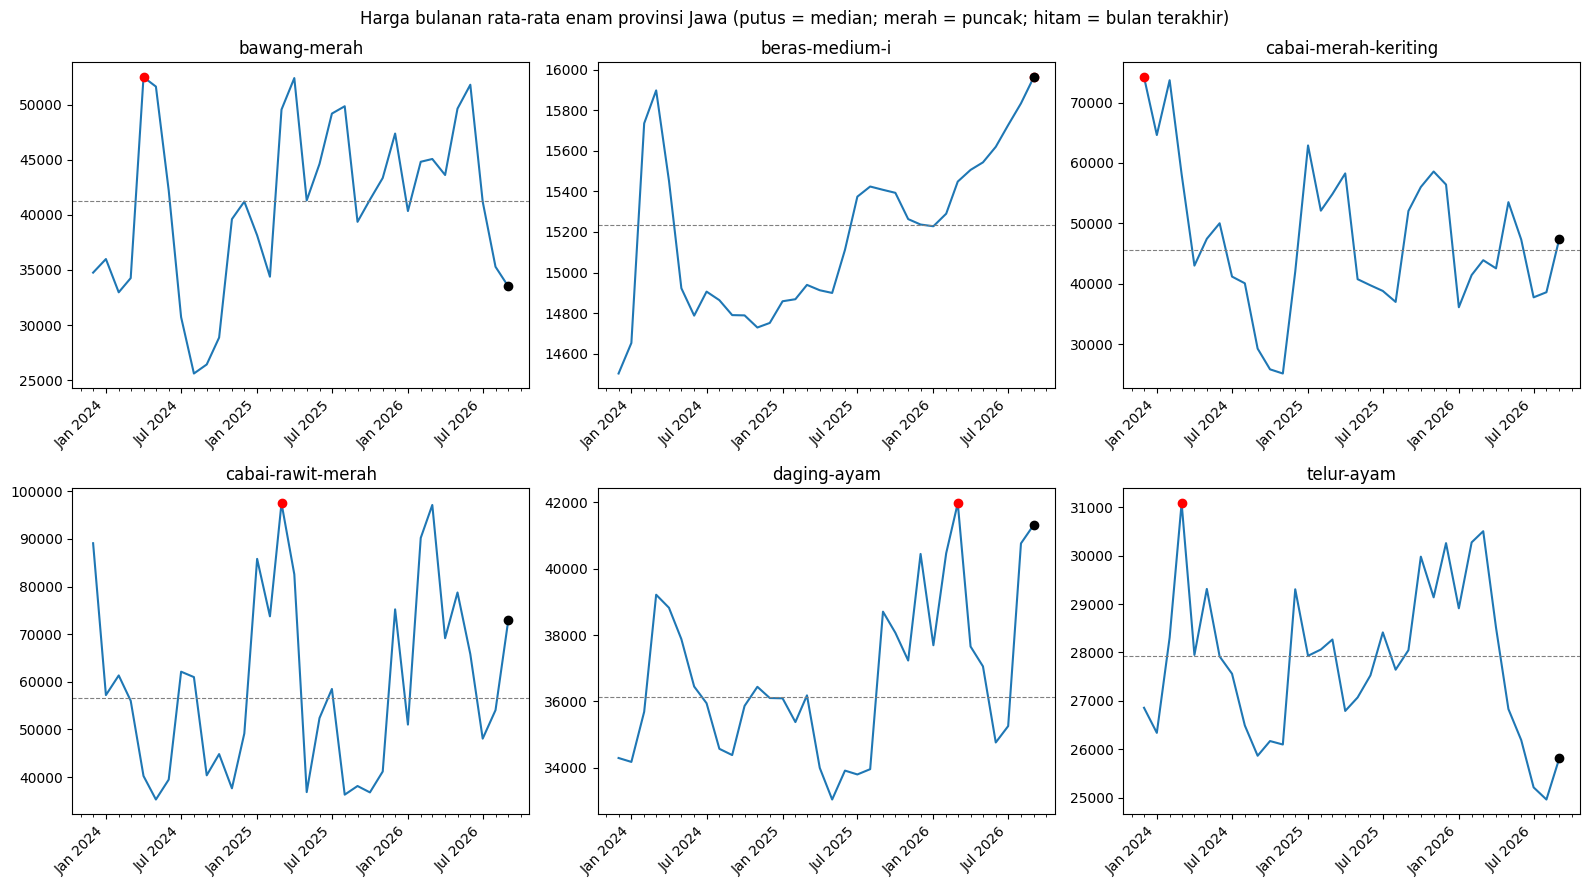

,harga_terakhir,median,puncak,bulan_puncak,vs_median_%,vs_puncak_%
komoditas,,,,,,
bawang-merah,33500.0,41255.0,52491.0,2024-04,-18.8,-36.2
beras-medium-i,15962.0,15232.0,15962.0,2026-09,4.8,0.0
cabai-merah-keriting,47425.0,45609.0,74209.0,2023-12,4.0,-36.1
cabai-rawit-merah,73002.0,56622.0,97523.0,2025-03,28.9,-25.1
daging-ayam,41324.0,36142.0,41977.0,2026-03,14.3,-1.6
telur-ayam,25811.0,27925.0,31083.0,2024-03,-7.6,-17.0


In [73]:
import os
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.ticker import FuncFormatter

OUT = f"{BASE}/output"
os.makedirs(OUT, exist_ok=True)

BULAN_ID = ["Jan", "Feb", "Mar", "Apr", "Mei", "Jun", "Jul", "Agu", "Sep", "Okt", "Nov", "Des"]

def label_bulan(x, pos=None):
    d = mdates.num2date(x)
    return f"{BULAN_ID[d.month - 1]} {d.year}"

# ---------- grafik tren ----------
fig, axes = plt.subplots(2, 3, figsize=(16, 9), sharex=True)
for ax, k in zip(axes.flat, nas.columns):
    s = nas[k]
    x = s.index.to_timestamp()
    ax.plot(x, s.values)
    ax.axhline(s.median(), ls="--", lw=0.8, color="gray")                    # median seluruh periode
    ax.scatter(s.idxmax().to_timestamp(), s.max(), color="red", zorder=3)     # puncak
    ax.scatter(x[-1], s.iloc[-1], color="black", zorder=3)                    # bulan terakhir
    ax.set_title(k)

    # sumbu x: label tiap Januari dan Juli, tanda kecil tiap bulan
    ax.xaxis.set_major_locator(mdates.MonthLocator(bymonth=[1, 7]))
    ax.xaxis.set_minor_locator(mdates.MonthLocator())
    ax.xaxis.set_major_formatter(FuncFormatter(label_bulan))
    ax.tick_params(axis="x", labelbottom=True, labelrotation=45)              # tampil di semua grafik
    for lab in ax.get_xticklabels():
        lab.set_ha("right")

fig.suptitle("Harga bulanan rata-rata enam provinsi Jawa (putus = median; merah = puncak; hitam = bulan terakhir)")
fig.tight_layout()
fig.savefig(f"{OUT}/tren_harga.png", dpi=150)
plt.show()

# ---------- tabel ringkasan ----------
ringkas = pd.DataFrame({
    "harga_terakhir": nas.iloc[-1],
    "median": nas.median(),
    "puncak": nas.max(),
    "bulan_puncak": nas.idxmax().astype(str),
}).round(0)
ringkas["vs_median_%"] = ((ringkas["harga_terakhir"] / ringkas["median"] - 1) * 100).round(1)
ringkas["vs_puncak_%"] = ((ringkas["harga_terakhir"] / ringkas["puncak"] - 1) * 100).round(1)
display(ringkas)

In [74]:
#Perbandingan Antar Provinsi

bulan_akhir, bulan_lalu_thn = pd.Period("2026-09"), pd.Period("2025-09")

# (a) selisih harga antarprovinsi di bulan terakhir
harga_akhir = prov[prov["bulan"] == bulan_akhir].pivot(index="provinsi", columns="komoditas", values="harga_bln")
selisih = ((harga_akhir.max() / harga_akhir.min() - 1) * 100).round(1)
print("Harga September 2026 per provinsi:")
display(harga_akhir.round(0))
print("Selisih harga tertinggi vs terendah antarprovinsi (%):")
display(selisih)

# (b) YoY per provinsi
pv = prov.pivot_table(index=["komoditas", "provinsi"], columns="bulan", values="harga_bln")
yoy_prov = ((pv[bulan_akhir] / pv[bulan_lalu_thn] - 1) * 100).unstack("komoditas").round(1)
print("YoY September 2026 per provinsi (%):")
display(yoy_prov)


Harga September 2026 per provinsi:


komoditas,bawang-merah,beras-medium-i,cabai-merah-keriting,cabai-rawit-merah,daging-ayam,telur-ayam
provinsi,,,,,,
Banten,35016.0,16350.0,50566.0,76900.0,42909.0,26200.0
DI Yogyakarta,37500.0,15373.0,44602.0,67898.0,40932.0,25555.0
DKI Jakarta,37336.0,17050.0,54641.0,83118.0,42636.0,26452.0
Jawa Barat,33380.0,15830.0,53668.0,78059.0,40623.0,26482.0
Jawa Tengah,29798.0,16025.0,43782.0,67566.0,40632.0,25123.0
Jawa Timur,27968.0,15148.0,37289.0,64470.0,40211.0,25057.0


Selisih harga tertinggi vs terendah antarprovinsi (%):


,0
komoditas,
bawang-merah,34.1
beras-medium-i,12.6
cabai-merah-keriting,46.5
cabai-rawit-merah,28.9
daging-ayam,6.7
telur-ayam,5.7


YoY September 2026 per provinsi (%):


komoditas,bawang-merah,beras-medium-i,cabai-merah-keriting,cabai-rawit-merah,daging-ayam,telur-ayam
provinsi,,,,,,
Banten,-13.1,5.5,-11.6,87.3,5.3,-7.6
DI Yogyakarta,-7.3,2.8,-0.4,113.5,10.5,-9.1
DKI Jakarta,-11.3,2.7,-11.3,72.6,4.3,-7.5
Jawa Barat,-15.8,4.4,-7.0,78.0,4.3,-7.2
Jawa Tengah,-21.4,3.3,-9.0,97.7,8.7,-7.9
Jawa Timur,-21.8,2.9,-13.2,117.2,8.0,-8.5


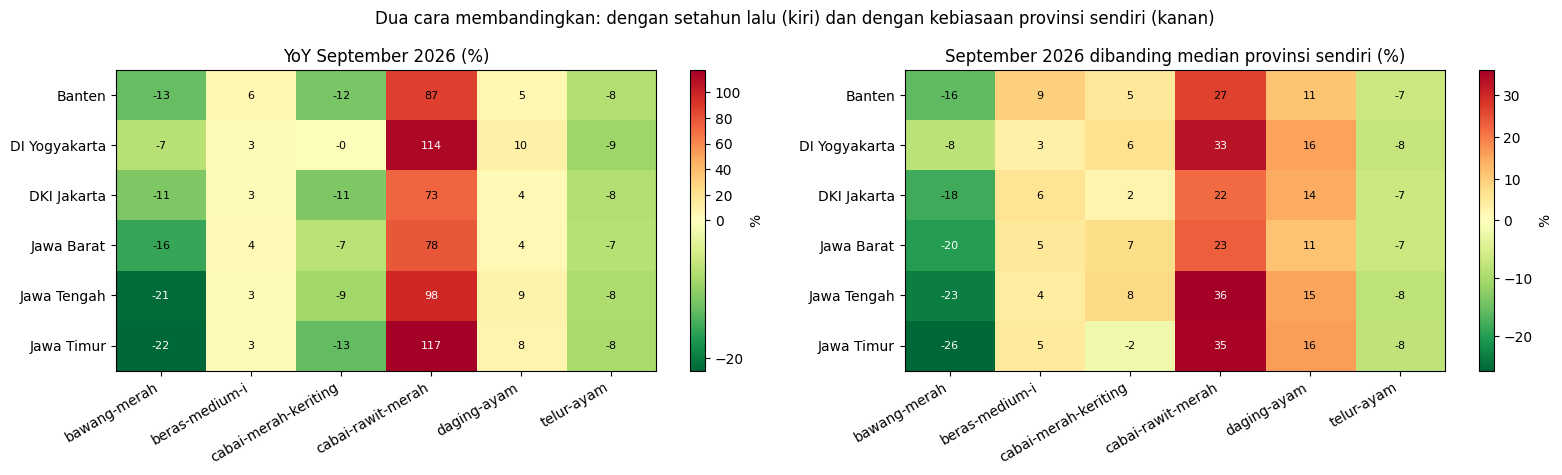

,selisih_rp_vs_median,vs_median_%,vs_rata2_%,z_skor,persentil
provinsi,,,,,
Banten,16134.8,26.6,19.3,0.6,73.5
DI Yogyakarta,16863.8,33.0,26.4,0.8,79.4
DKI Jakarta,14780.6,21.6,18.4,0.6,73.5
Jawa Barat,14693.6,23.2,21.3,0.7,76.5
Jawa Tengah,17858.4,35.9,27.3,0.8,76.5
Jawa Timur,16749.0,35.1,29.0,0.8,76.5


z-skor (berapa simpangan baku di atas/bawah rata-rata riwayat sendiri):


komoditas,bawang-merah,beras-medium-i,cabai-merah-keriting,cabai-rawit-merah,daging-ayam,telur-ayam
provinsi,,,,,,
Banten,-0.8,2.0,0.1,0.6,2.0,-1.3
DI Yogyakarta,-0.3,1.2,0.1,0.8,2.0,-1.3
DKI Jakarta,-1.1,1.6,-0.1,0.6,1.7,-1.3
Jawa Barat,-1.0,2.0,0.1,0.7,1.7,-1.2
Jawa Tengah,-1.2,1.8,0.1,0.8,1.9,-1.3
Jawa Timur,-1.2,1.6,-0.3,0.8,2.0,-1.2


persentil berdasarkan komoditas


komoditas,bawang-merah,beras-medium-i,cabai-merah-keriting,cabai-rawit-merah,daging-ayam,telur-ayam
provinsi,,,,,,
Banten,23.5,97.1,58.8,73.5,97.1,11.8
DI Yogyakarta,32.4,88.2,61.8,79.4,97.1,8.8
DKI Jakarta,17.6,100.0,55.9,73.5,94.1,11.8
Jawa Barat,17.6,97.1,58.8,76.5,94.1,14.7
Jawa Tengah,14.7,100.0,58.8,76.5,97.1,8.8
Jawa Timur,14.7,97.1,44.1,76.5,97.1,8.8


In [75]:
# YoY per provinsi & perbandingan dengan median provinsi sendiri

from matplotlib.colors import TwoSlopeNorm

vs_med = ((pv[bulan_akhir] / pv.median(axis=1) - 1) * 100).unstack("komoditas").round(1)

def peta_panas(ax, tabel, judul):
    v = tabel.values
    norm = TwoSlopeNorm(vmin=min(v.min(), -1), vcenter=0, vmax=max(v.max(), 1))   # warna berpusat di nol
    im = ax.imshow(v, cmap="RdYlGn_r", norm=norm, aspect="auto")
    ax.set_xticks(range(tabel.shape[1]), tabel.columns, rotation=30, ha="right")
    ax.set_yticks(range(tabel.shape[0]), tabel.index)
    for i in range(v.shape[0]):
        for j in range(v.shape[1]):
            n = float(norm(v[i, j]))
            warna = "white" if (n < 0.12 or n > 0.88) else "black"                  # teks terang di sel gelap
            ax.text(j, i, f"{v[i, j]:.0f}", ha="center", va="center", fontsize=8, color=warna)
    ax.set_title(judul)
    return im

fig, axes = plt.subplots(1, 2, figsize=(16, 4.8))
im1 = peta_panas(axes[0], yoy_prov, "YoY September 2026 (%)")
im2 = peta_panas(axes[1], vs_med, "September 2026 dibanding median provinsi sendiri (%)")
fig.colorbar(im1, ax=axes[0], label="%")
fig.colorbar(im2, ax=axes[1], label="%")
fig.suptitle("Dua cara membandingkan: dengan setahun lalu (kiri) dan dengan kebiasaan provinsi sendiri (kanan)")
fig.tight_layout()
fig.savefig(f"{OUT}/peta_panas_yoy_vs_median.png", dpi=150)
plt.show()

#persentil dan z-skor
rata = pv.mean(axis=1)
simpang = pv.std(axis=1)
median_prov = pv.median(axis=1)

ukuran = pd.DataFrame({
    "selisih_rp_vs_median": pv[bulan_akhir] - median_prov,
    "vs_median_%": (pv[bulan_akhir] / median_prov - 1) * 100,
    "vs_rata2_%": (pv[bulan_akhir] / rata - 1) * 100,
    "z_skor": (pv[bulan_akhir] - rata) / simpang,
    "persentil": pv.apply(lambda r: (r.dropna() <= r[bulan_akhir]).mean() * 100, axis=1),
}).round(1)

display(ukuran.loc["cabai-rawit-merah"])
print("z-skor (berapa simpangan baku di atas/bawah rata-rata riwayat sendiri):")
display(ukuran["z_skor"].unstack("komoditas"))

print("persentil berdasarkan komoditas")
display(ukuran["persentil"].unstack("komoditas"))

#### Dari tabel didapatkan

1. Selisih rupiah cabai rawit merah hampir sama di semua provinsi, hanya Rp14,7 sampai Rp17,9 ribu. Perbedaan persentase 21,6% sampai 35,9% sebagian besar berasal dari median yang lebih kecil di Jawa Tengah dan Jawa Timur. Jawa Tengah +Rp17,9 ribu dan DKI Jakarta +Rp14,8 ribu hanya berbeda sekitar Rp3 ribu, tapi persentasenya berbeda 14 poin.
2. Rata-rata mengecilkan semua persentase sekitar 2 sampai 9 poin untuk cabai rawit, karena rata-rata lebih tinggi dari median.
3. Jawa Tengah, Jawa Timur, dan DI Yogyakarta menjadi wilayah selalu ada di tiga besar, baik memakai median, rata-rata maupun z-skor. Yang bergeser hanya urutan antara Jawa Tengah dan Jawa Timur. DKI Jakarta selalu paling bawah atau hampir paling bawah.



Perubahan harga September 2026 dibanding Agustus 2026 (%):


komoditas,bawang-merah,beras-medium-i,cabai-merah-keriting,cabai-rawit-merah,daging-ayam,telur-ayam
provinsi,,,,,,
Banten,-5.3,0.4,23.0,35.9,1.1,0.7
DI Yogyakarta,-5.0,2.3,27.3,34.0,1.6,3.9
DKI Jakarta,-3.1,0.0,25.9,33.9,0.9,3.2
Jawa Barat,-4.5,1.1,26.2,36.0,-1.4,4.6
Jawa Tengah,-6.0,0.8,28.6,40.9,2.3,4.0
Jawa Timur,-7.0,0.5,5.1,29.8,4.0,4.2


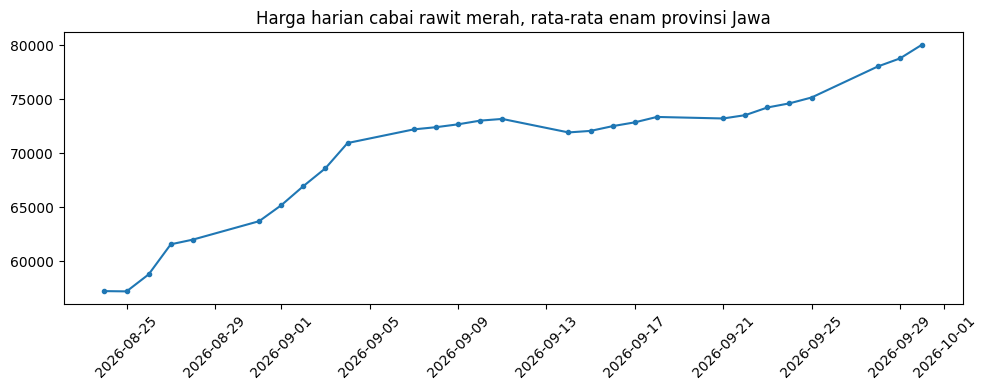

In [76]:
#lonjakan september per provinsi

# (a) perubahan bulanan (MoM) September 2026 per provinsi
sep = prov[prov["bulan"] == bulan_akhir].pivot(index="provinsi", columns="komoditas", values="mtm_pct").round(1)
print("Perubahan harga September 2026 dibanding Agustus 2026 (%):")
display(sep)

# (b) harga harian cabai rawit sejak akhir Agustus (rata-rata enam provinsi)
harian = pd.read_csv(f"{CLEAN}/pihps_harian_bersih.csv", parse_dates=["tanggal"])
cr = harian[(harian["jenis"] == "provinsi") & (harian["komoditas"] == "cabai-rawit-merah")
            & (harian["tanggal"] >= "2026-08-24")]
lintasan = cr.groupby("tanggal")["harga_bersih"].mean().round(0)

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(lintasan.index, lintasan.values, marker="o", ms=3)
ax.set_title("Harga harian cabai rawit merah, rata-rata enam provinsi Jawa")
ax.tick_params(axis="x", labelrotation=45)
fig.tight_layout()
fig.savefig(f"{OUT}/cabai_rawit_harian.png", dpi=150)
plt.show()

hasil :

* Cabai rawit naik 29,8% (Jawa Timur) sampai 40,9% (Jawa Tengah) di semua provinsi
* Cabai merah keriting naik 23-29% di lima provinsi tapi hanya 5,1% di Jawa Timur.
* Bawang merah turun 3-7%
* Beras (0–2,3%), daging ayam (−1,4% sampai +4,0%), dan telur (+0,7% sampai +4,6%) berubah kecil.

In [77]:
#hubungan di inflasi

from scipy.stats import spearmanr

gabung = pd.read_csv(f"{CLEAN}/gabungan_harga_inflasi.csv")
gabung["bulan"] = pd.PeriodIndex(gabung["bulan"], freq="M")
print(gabung.shape, gabung["bulan"].min(), gabung["bulan"].max())

# (a) korelasi Spearman per komoditas x provinsi
baris = []
for (k, p), d in gabung.groupby(["komoditas", "provinsi"]):
    r, pval = spearmanr(d["mtm_pct"], d["inflasi_mtm"])
    baris.append({"komoditas": k, "provinsi": p, "rho": r, "p": pval, "n": len(d)})
hub = pd.DataFrame(baris)

ring = hub.groupby("komoditas").agg(
    rho_rata2=("rho", "mean"),
    n_positif=("rho", lambda x: (x > 0).sum()),
    n_signif=("p", lambda x: (x < 0.05).sum()),
    n_pasang=("rho", "size")).round(2)
print("Korelasi perubahan harga vs inflasi, per komoditas (ringkasan enam provinsi):")
display(ring)

# (b) indeks gabungan: rata-rata perubahan harga enam komoditas
idx = (gabung.groupby(["provinsi", "bulan"])
       .agg(idx_pangan=("mtm_pct", "mean"), inflasi_mtm=("inflasi_mtm", "first")).reset_index())
baris = []
for p, d in idx.groupby("provinsi"):
    r, pval = spearmanr(d["idx_pangan"], d["inflasi_mtm"])
    baris.append({"provinsi": p, "rho": r, "p": pval})
print("Indeks gabungan enam komoditas vs inflasi, per provinsi:")
display(pd.DataFrame(baris).round(3))

# (c) jeda 1 bulan: harga bulan lalu vs inflasi bulan ini
gabung = gabung.sort_values(["komoditas", "provinsi", "bulan"])
gabung["mtm_lag1"] = gabung.groupby(["komoditas", "provinsi"])["mtm_pct"].shift(1)
baris = []
for (k, p), d in gabung.dropna(subset=["mtm_lag1"]).groupby(["komoditas", "provinsi"]):
    r, pval = spearmanr(d["mtm_lag1"], d["inflasi_mtm"])
    baris.append({"komoditas": k, "provinsi": p, "rho": r, "p": pval})
lag = pd.DataFrame(baris)
print("Signifikan (p<0,05):", int((lag["p"] < 0.05).sum()), "dari", len(lag),
      "| p terkecil:", round(float(lag["p"].min()), 3))
display(lag.groupby("komoditas")["rho"].mean().round(2).to_frame("rho_rata2"))

(1152, 11) 2024-01 2026-08
Korelasi perubahan harga vs inflasi, per komoditas (ringkasan enam provinsi):


,rho_rata2,n_positif,n_signif,n_pasang
komoditas,,,,
bawang-merah,0.51,6,6,6
beras-medium-i,0.17,6,1,6
cabai-merah-keriting,0.37,6,4,6
cabai-rawit-merah,0.39,6,6,6
daging-ayam,0.39,6,4,6
telur-ayam,0.40,6,5,6


Indeks gabungan enam komoditas vs inflasi, per provinsi:


,provinsi,rho,p
0,Banten,0.533,0.002
1,DI Yogyakarta,0.579,0.001
2,DKI Jakarta,0.533,0.002
3,Jawa Barat,0.576,0.001
4,Jawa Tengah,0.548,0.001
5,Jawa Timur,0.538,0.002


Signifikan (p<0,05): 0 dari 36 | p terkecil: 0.132


,rho_rata2
komoditas,
bawang-merah,-0.01
beras-medium-i,0.10
cabai-merah-keriting,-0.13
cabai-rawit-merah,-0.15
daging-ayam,0.21
telur-ayam,0.10


In [78]:
# hubungan dg inflasi

from scipy.stats import spearmanr, rankdata

gabung = pd.read_csv(f"{CLEAN}/gabungan_harga_inflasi.csv")
gabung["bulan"] = pd.PeriodIndex(gabung["bulan"], freq="M")
print(gabung.shape, gabung["bulan"].min(), gabung["bulan"].max())

# (a) korelasi Spearman per komoditas x provinsi
baris = []
for (k, p), d in gabung.groupby(["komoditas", "provinsi"]):
    r, pval = spearmanr(d["mtm_pct"], d["inflasi_mtm"])
    baris.append({"komoditas": k, "provinsi": p, "rho": r, "p": pval, "n": len(d)})
hub = pd.DataFrame(baris)

ring = hub.groupby("komoditas").agg(
    rho_rata2=("rho", "mean"),
    n_positif=("rho", lambda x: (x > 0).sum()),
    n_signif=("p", lambda x: (x < 0.05).sum()),
    n_pasang=("rho", "size")).round(2)
print("Korelasi perubahan harga vs inflasi, per komoditas (ringkasan enam provinsi):")
display(ring)

# (b) indeks gabungan: rata-rata perubahan harga enam komoditas
idx = (gabung.groupby(["provinsi", "bulan"])
       .agg(idx_pangan=("mtm_pct", "mean"), inflasi_mtm=("inflasi_mtm", "first")).reset_index())
baris = []
for p, d in idx.groupby("provinsi"):
    r, pval = spearmanr(d["idx_pangan"], d["inflasi_mtm"])
    baris.append({"provinsi": p, "rho": r, "p": pval})
print("Indeks gabungan enam komoditas vs inflasi, per provinsi:")
display(pd.DataFrame(baris).round(3))

# (c) jeda 1 bulan: harga bulan lalu vs inflasi bulan ini
gabung = gabung.sort_values(["komoditas", "provinsi", "bulan"])
gabung["mtm_lag1"] = gabung.groupby(["komoditas", "provinsi"])["mtm_pct"].shift(1)
baris = []
for (k, p), d in gabung.dropna(subset=["mtm_lag1"]).groupby(["komoditas", "provinsi"]):
    r, pval = spearmanr(d["mtm_lag1"], d["inflasi_mtm"])
    baris.append({"komoditas": k, "provinsi": p, "rho": r})
print("Jeda 1 bulan (harga bulan lalu vs inflasi bulan ini), rata-rata rho per komoditas:")
display(pd.DataFrame(baris).groupby("komoditas")["rho"].mean().round(2).to_frame("rho_rata2"))

# (d) tabel langkah demi langkah menghitung rho untuk SATU pasangan
def tabel_rho(komoditas, provinsi):
    t = gabung[(gabung["komoditas"] == komoditas) & (gabung["provinsi"] == provinsi)]
    t = t.sort_values("bulan")[["bulan", "mtm_pct", "inflasi_mtm"]].dropna().reset_index(drop=True)
    t["rank_harga"] = rankdata(t["mtm_pct"])          # peringkat 1 = terkecil
    t["rank_inflasi"] = rankdata(t["inflasi_mtm"])
    t["d"] = t["rank_harga"] - t["rank_inflasi"]       # selisih peringkat
    t["d2"] = t["d"] ** 2                              # selisih dikuadratkan

    n, s = len(t), t["d2"].sum()
    rho_rumus = 1 - 6 * s / (n * (n ** 2 - 1))
    rho_scipy, pval = spearmanr(t["mtm_pct"], t["inflasi_mtm"])
    kembar = int(t["mtm_pct"].duplicated().sum() + t["inflasi_mtm"].duplicated().sum())

    print(f"{komoditas} - {provinsi}")
    print(f"n = {n} bulan | jumlah d2 = {s:.0f}")
    print(f"rho dari rumus d2  = {rho_rumus:.3f}")
    print(f"rho dari spearmanr = {rho_scipy:.3f} (p = {pval:.4f})")
    print(f"jumlah nilai kembar = {kembar}" + ("  -> rumus d2 hanya pendekatan, pakai spearmanr" if kembar else ""))
    return t

# ganti nama di bawah untuk melihat pasangan lain (cek nama dengan gabung["komoditas"].unique())
tabel = tabel_rho("bawang-merah", "Jawa Barat")
display(tabel.round({"mtm_pct": 2, "inflasi_mtm": 2}))
print("Tiga bulan dengan selisih peringkat terbesar:")
display(tabel.loc[tabel["d"].abs().sort_values(ascending=False).index[:3]].round({"mtm_pct": 2, "inflasi_mtm": 2}))

(1152, 11) 2024-01 2026-08
Korelasi perubahan harga vs inflasi, per komoditas (ringkasan enam provinsi):


,rho_rata2,n_positif,n_signif,n_pasang
komoditas,,,,
bawang-merah,0.51,6,6,6
beras-medium-i,0.17,6,1,6
cabai-merah-keriting,0.37,6,4,6
cabai-rawit-merah,0.39,6,6,6
daging-ayam,0.39,6,4,6
telur-ayam,0.40,6,5,6


Indeks gabungan enam komoditas vs inflasi, per provinsi:


,provinsi,rho,p
0,Banten,0.533,0.002
1,DI Yogyakarta,0.579,0.001
2,DKI Jakarta,0.533,0.002
3,Jawa Barat,0.576,0.001
4,Jawa Tengah,0.548,0.001
5,Jawa Timur,0.538,0.002


Jeda 1 bulan (harga bulan lalu vs inflasi bulan ini), rata-rata rho per komoditas:


,rho_rata2
komoditas,
bawang-merah,-0.01
beras-medium-i,0.10
cabai-merah-keriting,-0.13
cabai-rawit-merah,-0.15
daging-ayam,0.21
telur-ayam,0.10


bawang-merah - Jawa Barat
n = 32 bulan | jumlah d2 = 2618
rho dari rumus d2  = 0.520
rho dari spearmanr = 0.520 (p = 0.0023)
jumlah nilai kembar = 0


,bulan,mtm_pct,inflasi_mtm,rank_harga,rank_inflasi,d,d2
0,2024-01,-0.51,0.16,16.0,16.0,0.0,0.0
1,2024-02,-10.32,0.45,9.0,27.0,-18.0,324.0
2,2024-03,5.82,0.52,24.0,28.0,-4.0,16.0
3,2024-04,61.52,0.13,32.0,14.0,18.0,324.0
4,2024-05,-4.64,-0.20,12.0,4.0,8.0,64.0
5,2024-06,-18.91,-0.09,5.0,8.0,-3.0,9.0
6,2024-07,-25.52,0.05,1.0,11.0,-10.0,100.0
7,2024-08,-14.91,0.07,7.0,13.0,-6.0,36.0
8,2024-09,1.19,-0.18,17.0,5.0,12.0,144.0
9,2024-10,10.14,0.07,26.0,12.0,14.0,196.0


Tiga bulan dengan selisih peringkat terbesar:


,bulan,mtm_pct,inflasi_mtm,rank_harga,rank_inflasi,d,d2
1,2024-02,-10.32,0.45,9.0,27.0,-18.0,324.0
3,2024-04,61.52,0.13,32.0,14.0,18.0,324.0
26,2026-03,-1.71,0.54,14.0,29.0,-15.0,225.0


In [79]:
# korelasi inflasi antarprovinsi
infl_p = pd.read_csv(f"{CLEAN}/inflasi_provinsi_bulanan.csv")
piv = infl_p.pivot(index="bulan", columns="provinsi", values="inflasi_mtm")
c = piv.corr(method="spearman")
print("Rata-rata korelasi Spearman antarprovinsi:",
      round(float(c.values[np.triu_indices_from(c.values, k=1)].mean()), 2))
display(c.round(2))

Rata-rata korelasi Spearman antarprovinsi: 0.93


provinsi,Banten,DI Yogyakarta,DKI Jakarta,Jawa Barat,Jawa Tengah,Jawa Timur
provinsi,,,,,,
Banten,1.00,0.94,0.93,0.96,0.94,0.94
DI Yogyakarta,0.94,1.00,0.93,0.93,0.95,0.93
DKI Jakarta,0.93,0.93,1.00,0.88,0.92,0.87
Jawa Barat,0.96,0.93,0.88,1.00,0.96,0.96
Jawa Tengah,0.94,0.95,0.92,0.96,1.00,0.96
Jawa Timur,0.94,0.93,0.87,0.96,0.96,1.00


In [80]:
# simpan hasil

import os
OUT = f"{BASE}/output"
os.makedirs(OUT, exist_ok=True)

daftar = {
    "volatilitas": "vol",
    "yoy_jawa_bulanan": "yoy",
    "yoy_provinsi_sep2026": "yoy_prov",
    "mtm_sep2026_provinsi": "sep",
    "harga_bulanan_jawa": "nas",
    "ringkasan_tren": "ringkas",
    "korelasi_inflasi": "hub",
    "ringkasan_korelasi": "ring",
}
for nama, var in daftar.items():
    if var in globals():
        obj = globals()[var]
        obj.to_csv(f"{OUT}/{nama}.csv", index=not isinstance(obj.index, pd.RangeIndex))
        print("tersimpan :", nama)
    else:
        print("dilewati  :", nama, f"(variabel {var} belum ada, jalankan sel yang membuatnya)")

print()
print(sorted(os.listdir(OUT)))

tersimpan : volatilitas
tersimpan : yoy_jawa_bulanan
tersimpan : yoy_provinsi_sep2026
tersimpan : mtm_sep2026_provinsi
tersimpan : harga_bulanan_jawa
tersimpan : ringkasan_tren
tersimpan : korelasi_inflasi
tersimpan : ringkasan_korelasi

['cabai_rawit_harian.png', 'harga_bulanan_jawa.csv', 'korelasi_inflasi.csv', 'mtm_sep2026_provinsi.csv', 'peta_panas_yoy_vs_median.png', 'ringkasan_korelasi.csv', 'ringkasan_tren.csv', 'tren_harga.png', 'volatilitas.csv', 'yoy_jawa_bulanan.csv', 'yoy_provinsi.png', 'yoy_provinsi_sep2026.csv']


## Kesimpulan

1. **Komoditas paling bergejolak adalah cabai rawit merah.** Simpangan baku perubahan harga bulanannya 35,3 poin persen, tertinggi dari enam komoditas, diikuti cabai merah keriting (23,2) dan bawang merah (18,3). Beras paling stabil (1,9). Peringkat tiga teratas tidak berubah pada ukuran gejolak lain (rentang antar-kuartil dan simpangan baku tanpa nilai ekstrem).

2. **Lonjakan harga 2026 terkonsentrasi pada cabai rawit merah dan terjadi di keenam provinsi.** Kenaikan tahunan (September 2026 dibanding September 2025) paling tinggi di Jawa Timur (+117,2%), DI Yogyakarta (+113,5%), dan Jawa Tengah (+97,7%), dengan rata-rata Jawa +91,5%. Dibanding kebiasaan harga provinsinya sendiri, ketiganya tetap paling jauh di atas median (+33% sampai +36%), tetapi selisihnya hanya sekitar 3 poin persen sehingga tidak diurutkan secara tegas. Sebagian selisih antarprovinsi berasal dari harga pembanding September 2025 yang rendah: di Jawa Timur dan DI Yogyakarta sekitar 38% di bawah median masing-masing, dibanding sekitar 30% di DKI Jakarta. Perlu dicatat bahwa harga rata-rata Jawa September 2026 (Rp73.002) masih 25,1% di bawah puncaknya pada Maret 2025, dan sebagian angka kenaikan tahunan berasal dari basis September 2025 yang rendah.

3. **Perubahan harga pangan berkorelasi positif dengan inflasi bulanan di bulan yang sama.** Korelasi Spearman rata-rata 0,37 (terkuat bawang merah 0,51, terlemah beras 0,17), dan indeks gabungan keenam komoditas berkorelasi 0,53–0,58 di semua provinsi (p < 0,01). Dengan jeda satu bulan tidak ada pasangan yang signifikan (0 dari 36; p terkecil 0,13), sehingga tidak ada bukti bahwa kenaikan harga mendahului inflasi bulan berikutnya. Hasil ini adalah korelasi, bukan sebab-akibat, dan keenam provinsi bergerak sangat serempak (korelasi inflasi antarprovinsi rata-rata 0,93), sehingga 36 pasangan tidak diperlakukan sebagai bukti yang saling bebas.

4. **Komoditas lain tidak ikut melonjak.** Telur (−8,0%), cabai merah keriting (−8,9%), dan bawang merah (−14,9%) lebih murah dibanding setahun lalu, sedangkan daging ayam (+6,8%) dan beras (+3,6%) naik pelan. Beras dan daging ayam berada di dekat titik tertingginya dalam periode ini.

5. **Posisi harga terhadap kebiasaan provinsi sendiri.** Pada September 2026, harga daging ayam dan beras jauh di atas kebiasaannya (z-skor 1,2–2,0; persentil 88–100), sedangkan cabai rawit tinggi tetapi masih dalam rentang gejolaknya (z-skor 0,6–0,8; persentil 74–79) dan cabai merah keriting berada di kisaran normal (persentil 44–62). Bawang merah (persentil 15–32) dan telur (persentil 9–15) berada di bawah kebiasaannya. Tingginya posisi beras mencerminkan kenaikan bertahap sepanjang 2026, bukan lonjakan.

**Keterbatasan:** cakupan enam provinsi di Pulau Jawa; inflasi provinsi dihitung sebagai rata-rata sederhana inflasi kota; data inflasi berhenti di Agustus 2026; faktor pendorong harga (kurs, cuaca, musiman) belum dianalisis.